# 2 · Training a building change detector

This notebook follows **L10 page 8, "Training your own model"** step by step: the same TorchGeo
`ChangeDetection` task with the FC-Siam-diff architecture, the same settings cell, Lightning `Trainer`
with checkpointing and early stopping on the validation F1-score, learning curves, a single test
evaluation, threshold tuning on the validation set, prediction maps and a growing results table.

## 1. Why training pairs have to be built

Page 8 trains on OSCD, where every sample is a *labeled image pair*: image T1, image T2 and an
analyst-drawn change mask. For the Lötschental we have something different: **one** date of imagery
(SWISSIMAGE 2023) with **building** labels (swissTLM3D). There are no real labeled change pairs, and the
event itself must stay unseen.

The pretrained model of pages 5–7, ChangeStar, faced exactly this problem, and its solution is the idea
we borrow. ChangeStar was introduced together with *single-temporal supervised learning* (STAR,
Zheng et al. 2021): take two **unpaired** labeled images, treat them as "before" and "after", and the
change label follows directly from their building masks. A pixel has changed if it is a building in
exactly one of the two images:

$$\text{change} = \text{building}_{T1} \;\text{XOR}\; \text{building}_{T2}$$

Changen2, the pretraining behind ChangeStar (page 4), pushes the same idea further with generated
image pairs. The labels are exact by construction, and the model is forced to learn what matters for
our question (a building is there in one image and not in the other) and to ignore everything else that
differs between the two images (forest, meadow, roads, rock, illumination).

We use two kinds of pairs:

| Pair type | T1 | T2 | Change label | Teaches the model |
|---|---|---|---|---|
| **STAR pair** | chip *i* | a different chip *j* | mask *i* XOR mask *j* | appearing and disappearing buildings are change; different background is not |
| **Same-place pair** | chip *i* | chip *i*, radiometrically distorted and shifted by up to 1 m | all zero | colour, brightness and small co-registration differences are **not** change (page 2) |

Everything else, model, loss, training loop, metrics, threshold choice, is page 8.

## 2. Workflow

### A. Imports and experiment settings

In [1]:
import json
import logging
import time
import warnings
from pathlib import Path

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
from lightning.pytorch import Trainer
from lightning.pytorch.accelerators import MPSAccelerator
from lightning.pytorch.callbacks import Callback, EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from scipy.ndimage import shift as nd_shift
from torch.utils.data import DataLoader, Dataset

from torchgeo.tasks import ChangeDetection

torch.set_float32_matmul_precision("medium")
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*exists and is not empty.*")
warnings.filterwarnings("ignore", ".*LeafSpec.*")
for name in ["lightning.pytorch", "lightning.fabric"]:  # hide routine status messages
    logging.getLogger(name).setLevel(logging.WARNING)

/Users/raphi.knecht/Documents/ChatGPT/SDS320/blatten_change_detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The next cell is the only one you need to edit. As on page 8: run once with the defaults, then change
**one** setting at a time and re-run everything.

In [2]:
# ============================ EXPERIMENT SETTINGS ============================
# --- Model -------------------------------------------------------------------
MODEL = "fcsiamdiff"  # siamese U-Net with a ResNet encoder; the two dates' features are subtracted
BACKBONE = "resnet18"  # "resnet18", "resnet34", "resnet50"
PRETRAINED = True  # start from ImageNet weights
FREEZE_BACKBONE = False  # True: train only the decoder

# --- Data --------------------------------------------------------------------
PATCH_SIZE = 256  # random training crops: 64, 128 or 256 (= full chip, 128 m)
AUGMENT = True  # random flips and 90-degree rotations, identical for both dates and the mask
SAME_PLACE_FRACTION = 0.3  # share of "no change" pairs built from one chip (see section 1)
PHOTOMETRIC = True  # independent brightness/contrast/colour/gamma changes per date (training only)
PAIRS_PER_EPOCH = 256  # random pairs drawn per training epoch

# --- Loss and optimization ----------------------------------------------------
LOSS = "dice"  # "bce", "dice", "focal" or "jaccard"
POS_WEIGHT = 10.0  # extra weight for change pixels, only used with LOSS = "bce"
LR = 1e-3  # learning rate
BATCH_SIZE = 8
MAX_EPOCHS = 30
PATIENCE = 8  # stop early if the validation F1 has not improved for this many epochs

# --- Evaluation and reproducibility --------------------------------------------
TUNE_THRESHOLD = True  # choose the probability threshold on the validation set (else 0.5)
SEED = 0  # random seed: change it to see how much results vary between runs
# ==============================================================================

EXPERIMENT = (
    f"{MODEL}-{BACKBONE}_p{PATCH_SIZE}_aug{int(AUGMENT)}_same{SAME_PLACE_FRACTION:g}"
    f"_photo{int(PHOTOMETRIC)}_{LOSS}_freeze{int(FREEZE_BACKBONE)}_lr{LR:g}_seed{SEED}"
)
L.seed_everything(SEED, workers=True)
print("Experiment:", EXPERIMENT)

Experiment: fcsiamdiff-resnet18_p256_aug1_same0.3_photo1_dice_freeze0_lr0.001_seed0


| Setting | Default here | What it controls |
|---|---|---|
| `MODEL`, `BACKBONE` | `"fcsiamdiff"`, `"resnet18"` | Architecture and size of the shared encoder (page 8 default) |
| `PATCH_SIZE` | `256` | Spatial context per training example; page 8 found this to matter most |
| `AUGMENT` | `True` | Random flips and rotations of the training pairs |
| `SAME_PLACE_FRACTION` | `0.3` | How often the model sees "same place, different look, no change" |
| `PHOTOMETRIC` | `True` | Simulates a second flight with different light and processing |
| `LOSS` | `"dice"` | What the model optimizes (page 8, step D) |
| `MAX_EPOCHS`, `PATIENCE` | `30`, `8` | Maximum training length and early stopping. Lower than page 8 (100/30) because one epoch here has 4× more pairs (256) and training runs on a laptop CPU (about 2 min per epoch) |
| `TUNE_THRESHOLD` | `True` | Choose the probability threshold on the validation set |

### B. Load and inspect the data

Notebook 1 cut the chips: Ferden, Kippel and Lauchernalp for training, Wiler for validation and
Fafleralp for testing. Blatten is not among them.

In [3]:
CHIPS = Path("data/chips")
OUT_DIR = Path("runs")  # checkpoints, training logs and the results table
OUT_DIR.mkdir(exist_ok=True)

chips = pd.read_csv(CHIPS / "chips.csv")


def load_split(split):
    """Load all image chips (N, 3, H, W) and building masks (N, H, W) of a split into memory."""
    ids = chips.loc[chips.split == split, "chip"].tolist()
    images, masks = [], []
    for chip_id in ids:
        with rasterio.open(CHIPS / split / "images" / f"{chip_id}.tif") as src:
            images.append(src.read())
        with rasterio.open(CHIPS / split / "masks" / f"{chip_id}.tif") as src:
            masks.append(src.read(1))
    return np.stack(images), np.stack(masks), ids


data = {split: load_split(split) for split in ["train", "val", "test"]}
for split, (images, masks, ids) in data.items():
    regions = sorted(chips.loc[chips.split == split, "region"].unique())
    print(f"{split:5s}: {len(ids):4d} chips from {', '.join(regions):28s} building pixels {100 * masks.mean():.1f}%")

# Normalization statistics from the TRAINING chips only (L06: no information from validation/test)
MEAN = data["train"][0].mean(axis=(0, 2, 3))
STD = data["train"][0].std(axis=(0, 2, 3))
print("Band mean:", MEAN.round(1), " std:", STD.round(1))

train:  380 chips from ferden, kippel, lauchernalp  building pixels 3.9%
val  :   40 chips from wiler                        building pixels 5.3%
test :   56 chips from fafleralp                    building pixels 0.7%


Band mean: [101.1 114.   86.8]  std: [42.6 40.9 39.7]


### C. Building the image pairs, data loading and augmentation

`ChangePairs` turns single-date chips into change samples in the same format as OSCD on page 8:
`image` with shape *(time, bands, height, width)* and a binary `mask` with shape *(1, height, width)*.

- For **training**, every call draws a new random partner and new radiometric distortions, so the
  model sees different pairs in every epoch (a strong form of data augmentation).
- For **validation and test**, the pairs are fixed: each chip gets one partner and one distortion,
  chosen with a fixed random seed per chip. Scores are therefore comparable between epochs and between
  experiments, exactly as page 8 requires.

In [4]:
def photometric(image, rng):
    """Change brightness, contrast, colour balance and gamma of one image (float, 0-255)."""
    image = image / 255.0
    image = image ** rng.uniform(0.8, 1.25)  # gamma
    gain = rng.uniform(0.85, 1.15) * rng.uniform(0.92, 1.08, size=(3, 1, 1))  # brightness and colour
    mean = image.mean()
    image = (image - mean) * rng.uniform(0.8, 1.2) + mean  # contrast
    return np.clip(image * gain, 0, 1) * 255.0


class ChangePairs(Dataset):
    """Bitemporal change samples built from single-date labeled chips (STAR pairs + same-place pairs)."""

    def __init__(self, images, masks, same_place_fraction, length=None, fixed=False, photometric_train=True, seed=0):
        self.images, self.masks = images, masks
        self.same_place_fraction = same_place_fraction
        self.length = length or len(images)
        self.fixed, self.photometric_train, self.seed = fixed, photometric_train, seed

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        rng = np.random.default_rng(self.seed + index) if self.fixed else np.random.default_rng()
        i = index if self.fixed else int(rng.integers(len(self.images)))
        image1, mask1 = self.images[i].astype("float32"), self.masks[i]
        if rng.random() < self.same_place_fraction:
            # Same place: a radiometrically different, slightly shifted copy, no change at all
            dy, dx = rng.integers(-2, 3, size=2)  # up to 2 pixels = 1 m co-registration error
            image2 = nd_shift(image1, (0, dy, dx), order=0, mode="nearest")
            image2 = photometric(image2, rng)
            change = np.zeros_like(mask1)
        else:
            # STAR pair: a different place; change where exactly one of the two has a building
            j = (i + 1 + int(rng.integers(len(self.images) - 1))) % len(self.images)
            image2, mask2 = self.images[j].astype("float32"), self.masks[j]
            change = (mask1 ^ mask2).astype("uint8")
            if rng.random() < 0.5:  # the second date usually looks different, too
                image2 = photometric(image2, rng)
        if not self.fixed and self.photometric_train:
            image1 = photometric(image1, rng)  # both dates vary independently in training
        if rng.random() < 0.5:  # random temporal order; XOR is symmetric, so the label stays the same
            image1, image2 = image2, image1
        pair = np.stack([image1, image2])  # (time, bands, height, width)
        return {"image": torch.from_numpy(pair).float(), "mask": torch.from_numpy(change[None]).long()}

The augmentation and normalization code is taken from page 8 unchanged: `flip_and_rotate()` applies
**the same** rotation and flip to both dates and the mask; validation and test always use the complete,
unaugmented 256 × 256 chips.

In [5]:
def flip_and_rotate(batch):
    """Apply the same random rotation and flip to both dates and the mask."""
    images, masks = batch["image"], batch["mask"]  # (B, T, C, H, W), (B, 1, H, W)
    for i in range(images.shape[0]):
        k = int(torch.randint(0, 4, (1,)))  # rotate by k * 90 degrees
        image = images[i].rot90(k, dims=(-2, -1))
        mask = masks[i].rot90(k, dims=(-2, -1))
        if torch.rand(1) < 0.5:  # mirror half of the samples
            image, mask = image.flip(-1), mask.flip(-1)
        images[i], masks[i] = image, mask
    return batch


def random_crop(batch, size):
    """Cut the same random `size` crop from both dates and the mask of every sample."""
    if size >= batch["image"].shape[-1]:
        return batch
    H = batch["image"].shape[-1]
    r, c = (int(v) for v in torch.randint(0, H - size + 1, (2,)))
    batch["image"] = batch["image"][..., r:r + size, c:c + size]
    batch["mask"] = batch["mask"][..., r:r + size, c:c + size]
    return batch


class LoetschentalChangeDataModule(L.LightningDataModule):
    """Lötschental change pairs with augmentation and full chips for validation and test."""

    def __init__(self, augment=True, patch_size=256, batch_size=8):
        super().__init__()
        self.augment, self.patch_size, self.batch_size = augment, patch_size, batch_size
        self.mean = torch.tensor(MEAN, dtype=torch.float32).view(1, 1, 3, 1, 1)
        self.std = torch.tensor(STD, dtype=torch.float32).view(1, 1, 3, 1, 1)

    def setup(self, stage):
        self.train_dataset = ChangePairs(*data["train"][:2], SAME_PLACE_FRACTION, length=PAIRS_PER_EPOCH,
                                         photometric_train=PHOTOMETRIC)
        self.val_dataset = ChangePairs(*data["val"][:2], SAME_PLACE_FRACTION, fixed=True, seed=1000)
        self.test_dataset = ChangePairs(*data["test"][:2], SAME_PLACE_FRACTION, fixed=True, seed=2000)

    def train_dataloader(self):
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True, num_workers=0)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, num_workers=0)

    def test_dataloader(self):
        return DataLoader(self.test_dataset, batch_size=self.batch_size, num_workers=0)

    def normalize(self, image):
        return (image - self.mean.to(image.device)) / self.std.to(image.device)

    def on_after_batch_transfer(self, batch, dataloader_idx):
        batch["image"] = self.normalize(batch["image"])
        if self.trainer is not None and self.trainer.training:
            batch = random_crop(batch, self.patch_size)
            if self.augment:
                batch = flip_and_rotate(batch)
        return batch


datamodule = LoetschentalChangeDataModule(augment=AUGMENT, patch_size=PATCH_SIZE, batch_size=BATCH_SIZE)
datamodule.setup("fit")

Before training, look at some of the fixed **validation** pairs. Each row is one sample: the two
"dates" and the change label the model has to reproduce.

Validation pairs: 40, changed pixels 6.7%, pairs without any change: 17


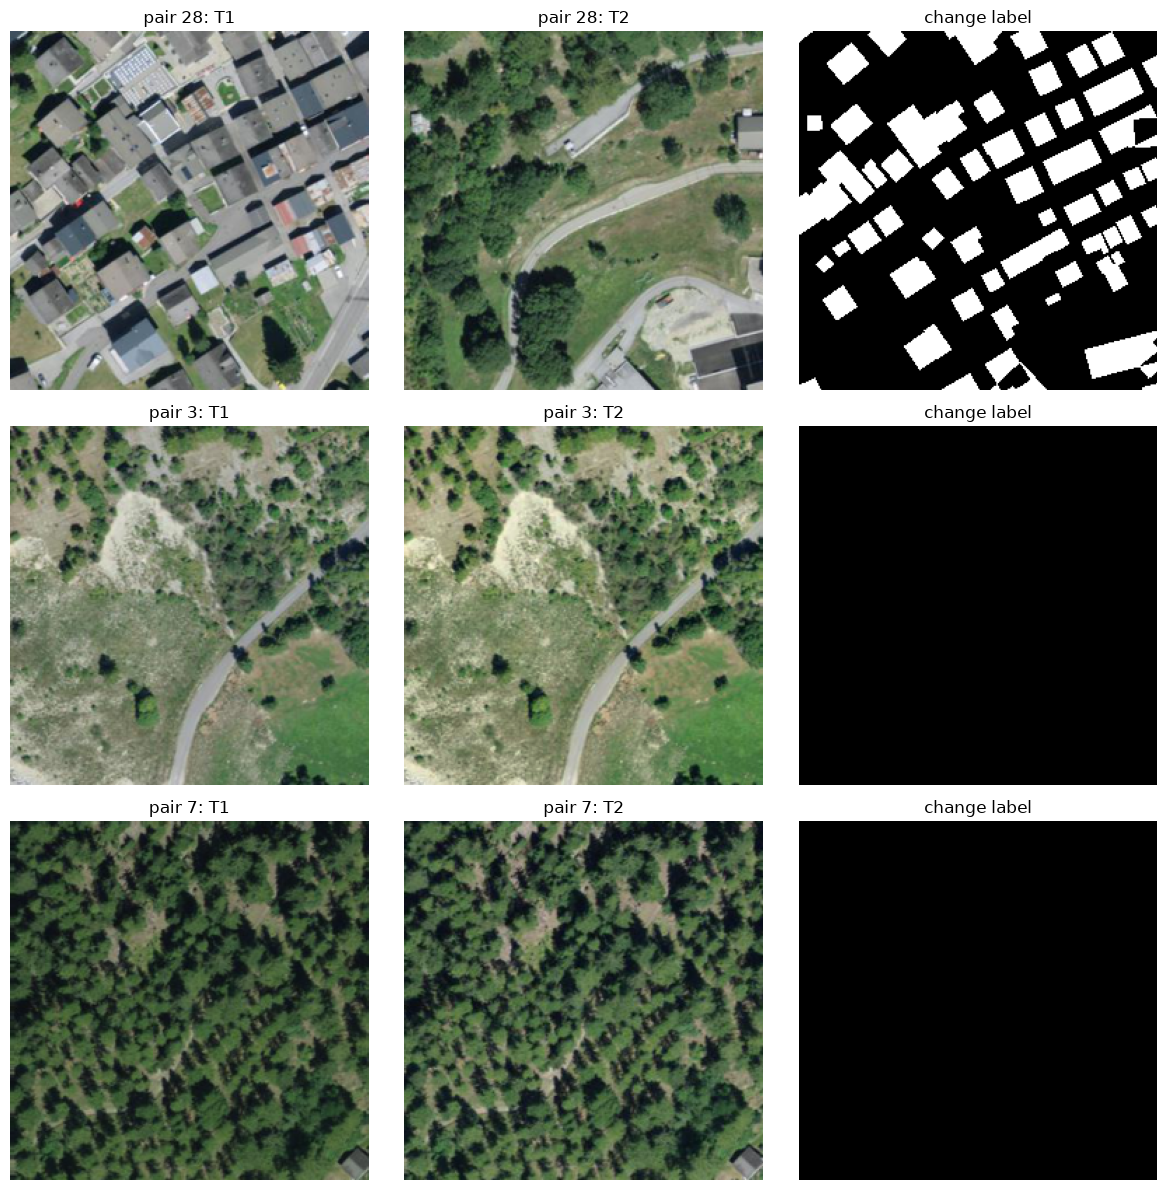

In [6]:
def show_pairs(dataset, indices, predictions=None, titles=None):
    columns = 3 if predictions is None else 4
    fig, axes = plt.subplots(len(indices), columns, figsize=(4 * columns, 4 * len(indices)))
    for row, idx in enumerate(indices):
        sample = dataset[idx]
        for t in range(2):
            axes[row, t].imshow(sample["image"][t].permute(1, 2, 0).numpy().astype("uint8"))
            axes[row, t].set_title(f"pair {idx}: T{t + 1}")
        axes[row, 2].imshow(sample["mask"][0], cmap="gray", vmin=0, vmax=1)
        axes[row, 2].set_title("change label" if titles is None else titles[row])
        if predictions is not None:
            axes[row, 3].imshow(predictions[row], cmap="gray", vmin=0, vmax=1)
            axes[row, 3].set_title("prediction")
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


val_change = [datamodule.val_dataset[i]["mask"].float().mean().item() for i in range(len(datamodule.val_dataset))]
print(f"Validation pairs: {len(val_change)}, changed pixels {100 * np.mean(val_change):.1f}%, "
      f"pairs without any change: {sum(v == 0 for v in val_change)}")
show_pairs(datamodule.val_dataset, [int(np.argmax(val_change)), 3, 7])

Note how few pixels change: the class imbalance from page 8 is here, too, which is why the Dice loss
is the default.

### D. Model and loss

Identical to page 8. FC-Siam-diff passes both dates through **the same** ResNet encoder and decodes the
*difference* of their features.

In [7]:
task = ChangeDetection(
    model=MODEL,
    backbone=BACKBONE,
    weights=PRETRAINED,
    freeze_backbone=FREEZE_BACKBONE,
    loss=LOSS,
    pos_weight=torch.tensor([POS_WEIGHT]) if LOSS == "bce" else None,
    in_channels=3,  # RGB bands per date
    lr=LR,
)

n_params = sum(p.numel() for p in task.model.parameters())
print(f"{MODEL} with {BACKBONE}: {n_params / 1e6:.1f} million parameters")

fcsiamdiff with resnet18: 14.3 million parameters


### E. Train the model

`ModelCheckpoint` keeps the epoch with the best validation F1, `EarlyStopping` ends training when it
stops improving, `CSVLogger` records all metrics (page 8, step E).

In [8]:
class PrintProgress(Callback):
    """Print a short progress line every few epochs."""

    def __init__(self, every=5):
        self.every = every

    def on_train_epoch_end(self, trainer, pl_module):
        epoch = trainer.current_epoch + 1
        if epoch % self.every == 0 or epoch == 1:
            m = trainer.callback_metrics
            print(
                f"epoch {epoch:3d} | train loss {m['train_loss']:.3f} | "
                f"val loss {m['val_loss']:.3f} | val F1 {m['val_AverageF1Score']:.3f}",
                flush=True,
            )


# Hardware: CUDA GPU > Apple GPU (MPS) > CPU. Lightning's own check is used for MPS, because
# PyTorch can report MPS on Intel Macs where Lightning cannot use it.
if torch.cuda.is_available():
    accelerator = "gpu"
elif MPSAccelerator.is_available():
    accelerator = "mps"
else:
    accelerator = "cpu"
print("Training on:", accelerator)

checkpoint_callback = ModelCheckpoint(
    monitor="val_AverageF1Score",
    mode="max",
    dirpath=OUT_DIR / "checkpoints" / EXPERIMENT,
    save_top_k=1,
)
early_stopping_callback = EarlyStopping(monitor="val_AverageF1Score", mode="max", patience=PATIENCE)
logger = CSVLogger(save_dir=OUT_DIR / "logs", name=EXPERIMENT)

trainer = Trainer(
    accelerator=accelerator,
    devices=1,
    callbacks=[checkpoint_callback, early_stopping_callback, PrintProgress()],
    logger=logger,
    log_every_n_steps=1,
    max_epochs=MAX_EPOCHS,
    enable_progress_bar=False,
    enable_model_summary=False,
)

start = time.time()
trainer.fit(model=task, datamodule=datamodule)
print(f"\nStopped after {trainer.current_epoch} epochs ({(time.time() - start) / 60:.1f} min)")
print(f"Best validation F1: {checkpoint_callback.best_model_score:.3f}")

Training on: cpu


epoch   1 | train loss 0.698 | val loss 0.830 | val F1 0.182


epoch   5 | train loss 0.273 | val loss 0.464 | val F1 0.537


epoch  10 | train loss 0.273 | val loss 0.315 | val F1 0.690


epoch  15 | train loss 0.247 | val loss 0.274 | val F1 0.734


epoch  20 | train loss 0.214 | val loss 0.303 | val F1 0.700


epoch  25 | train loss 0.235 | val loss 0.309 | val F1 0.696


epoch  30 | train loss 0.276 | val loss 0.283 | val F1 0.724



Stopped after 30 epochs (64.5 min)
Best validation F1: 0.757


### F. Learning curves

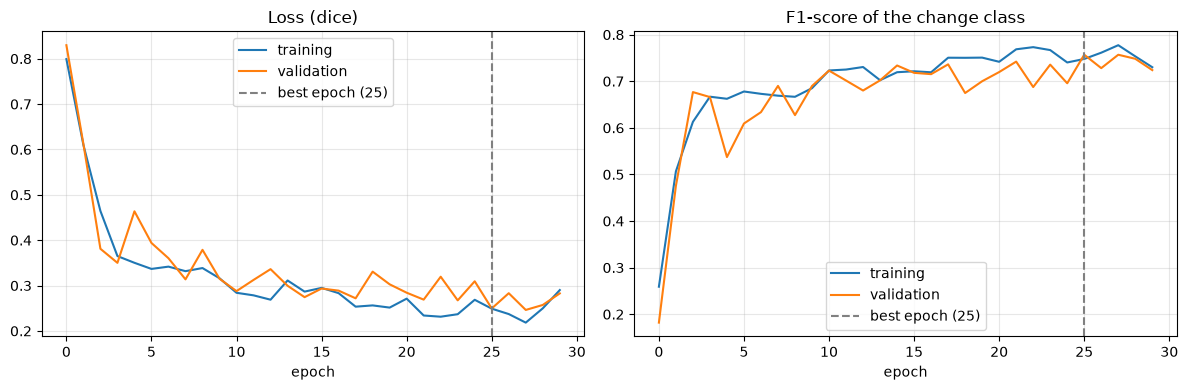

In [9]:
metrics = pd.read_csv(Path(logger.log_dir) / "metrics.csv")
per_epoch = metrics.groupby("epoch").mean(numeric_only=True)
best_epoch = per_epoch["val_AverageF1Score"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(per_epoch.index, per_epoch["train_loss"], label="training")
axes[0].plot(per_epoch.index, per_epoch["val_loss"], label="validation")
axes[0].set_title(f"Loss ({LOSS})")
axes[1].plot(per_epoch.index, per_epoch["train_AverageF1Score"], label="training")
axes[1].plot(per_epoch.index, per_epoch["val_AverageF1Score"], label="validation")
axes[1].set_title("F1-score of the change class")
for ax in axes:
    ax.axvline(best_epoch, color="grey", ls="--", label=f"best epoch ({best_epoch})")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(Path("figures") / "02_learning_curves.png", dpi=120)
plt.show()

Read the curves as on page 8: training and validation improving together means the model learns
patterns that generalize to a new village; a widening gap means overfitting. Here the training pairs
are re-drawn every epoch, so the training curve is itself noisy, and it is computed on *augmented*,
radiometrically distorted pairs, which are harder than the validation pairs.

### G. Evaluate on the test set

Only now do we touch the test set (Fafleralp), using the best checkpoint.

In [10]:
test_metrics = trainer.test(model=task, datamodule=datamodule, ckpt_path="best", verbose=False)[0]

pd.Series(
    {
        "Accuracy": test_metrics["test_OverallAccuracy"],
        "Precision": test_metrics["test_AveragePrecision"],
        "Recall": test_metrics["test_AverageRecall"],
        "F1-score": test_metrics["test_AverageF1Score"],
        "IoU": test_metrics["test_AverageJaccardIndex"],
    },
    name="test set, threshold 0.5",
).round(3).to_frame()

,"test set, threshold 0.5"
Accuracy,0.995
Precision,0.629
Recall,0.717
F1-score,0.670
IoU,0.504


As on page 8, accuracy is high only because almost all pixels are unchanged; **F1-score and IoU of
the change class** are what count.

### H. Tune the probability threshold

Chosen on the validation set, reported on the test set.

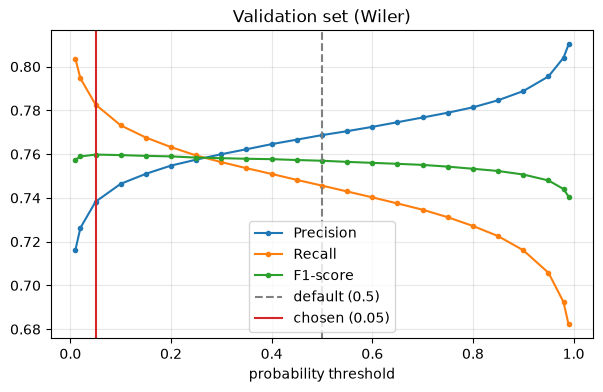

,Precision,Recall,F1-score,IoU
threshold 0.5,0.629,0.717,0.67,0.504
tuned threshold 0.05,0.583,0.759,0.66,0.492


In [11]:
best_task = ChangeDetection.load_from_checkpoint(checkpoint_callback.best_model_path)
best_task = best_task.to(task.device).eval()


def predict_split(dataset):
    """Return change probabilities and reference masks for all pairs of a dataset."""
    probs, masks = [], []
    for item in dataset:
        image = datamodule.normalize(item["image"].unsqueeze(0))
        with torch.no_grad():
            prob = best_task.predict_step({"image": image.to(best_task.device)}, 0)
        probs.append(prob.squeeze().cpu())
        masks.append(item["mask"].squeeze().bool())
    return torch.stack(probs), torch.stack(masks)


def scores(prob, mask, threshold):
    """Precision, recall, F1 and IoU of the change class at a given threshold."""
    pred = prob > threshold
    tp = (pred & mask).sum().item()
    fp = (pred & ~mask).sum().item()
    fn = (~pred & mask).sum().item()
    return {
        "Precision": tp / max(tp + fp, 1),
        "Recall": tp / max(tp + fn, 1),
        "F1-score": 2 * tp / max(2 * tp + fp + fn, 1),
        "IoU": tp / max(tp + fp + fn, 1),
    }


val_prob, val_mask = predict_split(datamodule.val_dataset)
thresholds = [0.01, 0.02] + [t / 100 for t in range(5, 96, 5)] + [0.98, 0.99]
val_scores = pd.DataFrame([scores(val_prob, val_mask, t) for t in thresholds], index=thresholds)
threshold = val_scores["F1-score"].idxmax() if TUNE_THRESHOLD else 0.5

ax = val_scores[["Precision", "Recall", "F1-score"]].plot(figsize=(7, 4), marker=".")
ax.axvline(0.5, color="grey", ls="--", label="default (0.5)")
ax.axvline(threshold, color="C3", label=f"chosen ({threshold:.2f})")
ax.set_xlabel("probability threshold")
ax.set_title("Validation set (Wiler)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

test_prob, test_mask = predict_split(datamodule.test_dataset)
pd.DataFrame(
    {
        "threshold 0.5": scores(test_prob, test_mask, 0.5),
        f"tuned threshold {threshold:.2f}": scores(test_prob, test_mask, threshold),
    }
).T.round(3)

**Reading the result (run with seed 0, 30 epochs on CPU).** The best checkpoint (epoch 25) reached a
validation F1 of 0.76 on Wiler. On the held-out Fafleralp test area the change class scores F1 ≈ 0.67 and
IoU ≈ 0.50. The validation F1 curve is almost flat between thresholds 0.05 and 0.95: a Dice-trained model
outputs probabilities close to 0 or 1, so the tuned threshold (0.05) trades a little precision for recall
but hardly changes F1, and on the test set it is even slightly worse than 0.5. Fafleralp is a hard test
area with few buildings (0.7% building pixels), so a few missed or extra blobs weigh heavily. The learning
curves were still rising when the 30-epoch budget ended, so a longer run (or a GPU) would likely help.
Predicted changes are rounded blobs rather than sharp rectangles, which is typical at 0.5 m resolution.

### I. Visualize predictions

The four test pairs with the most change, each with its own F1-score.

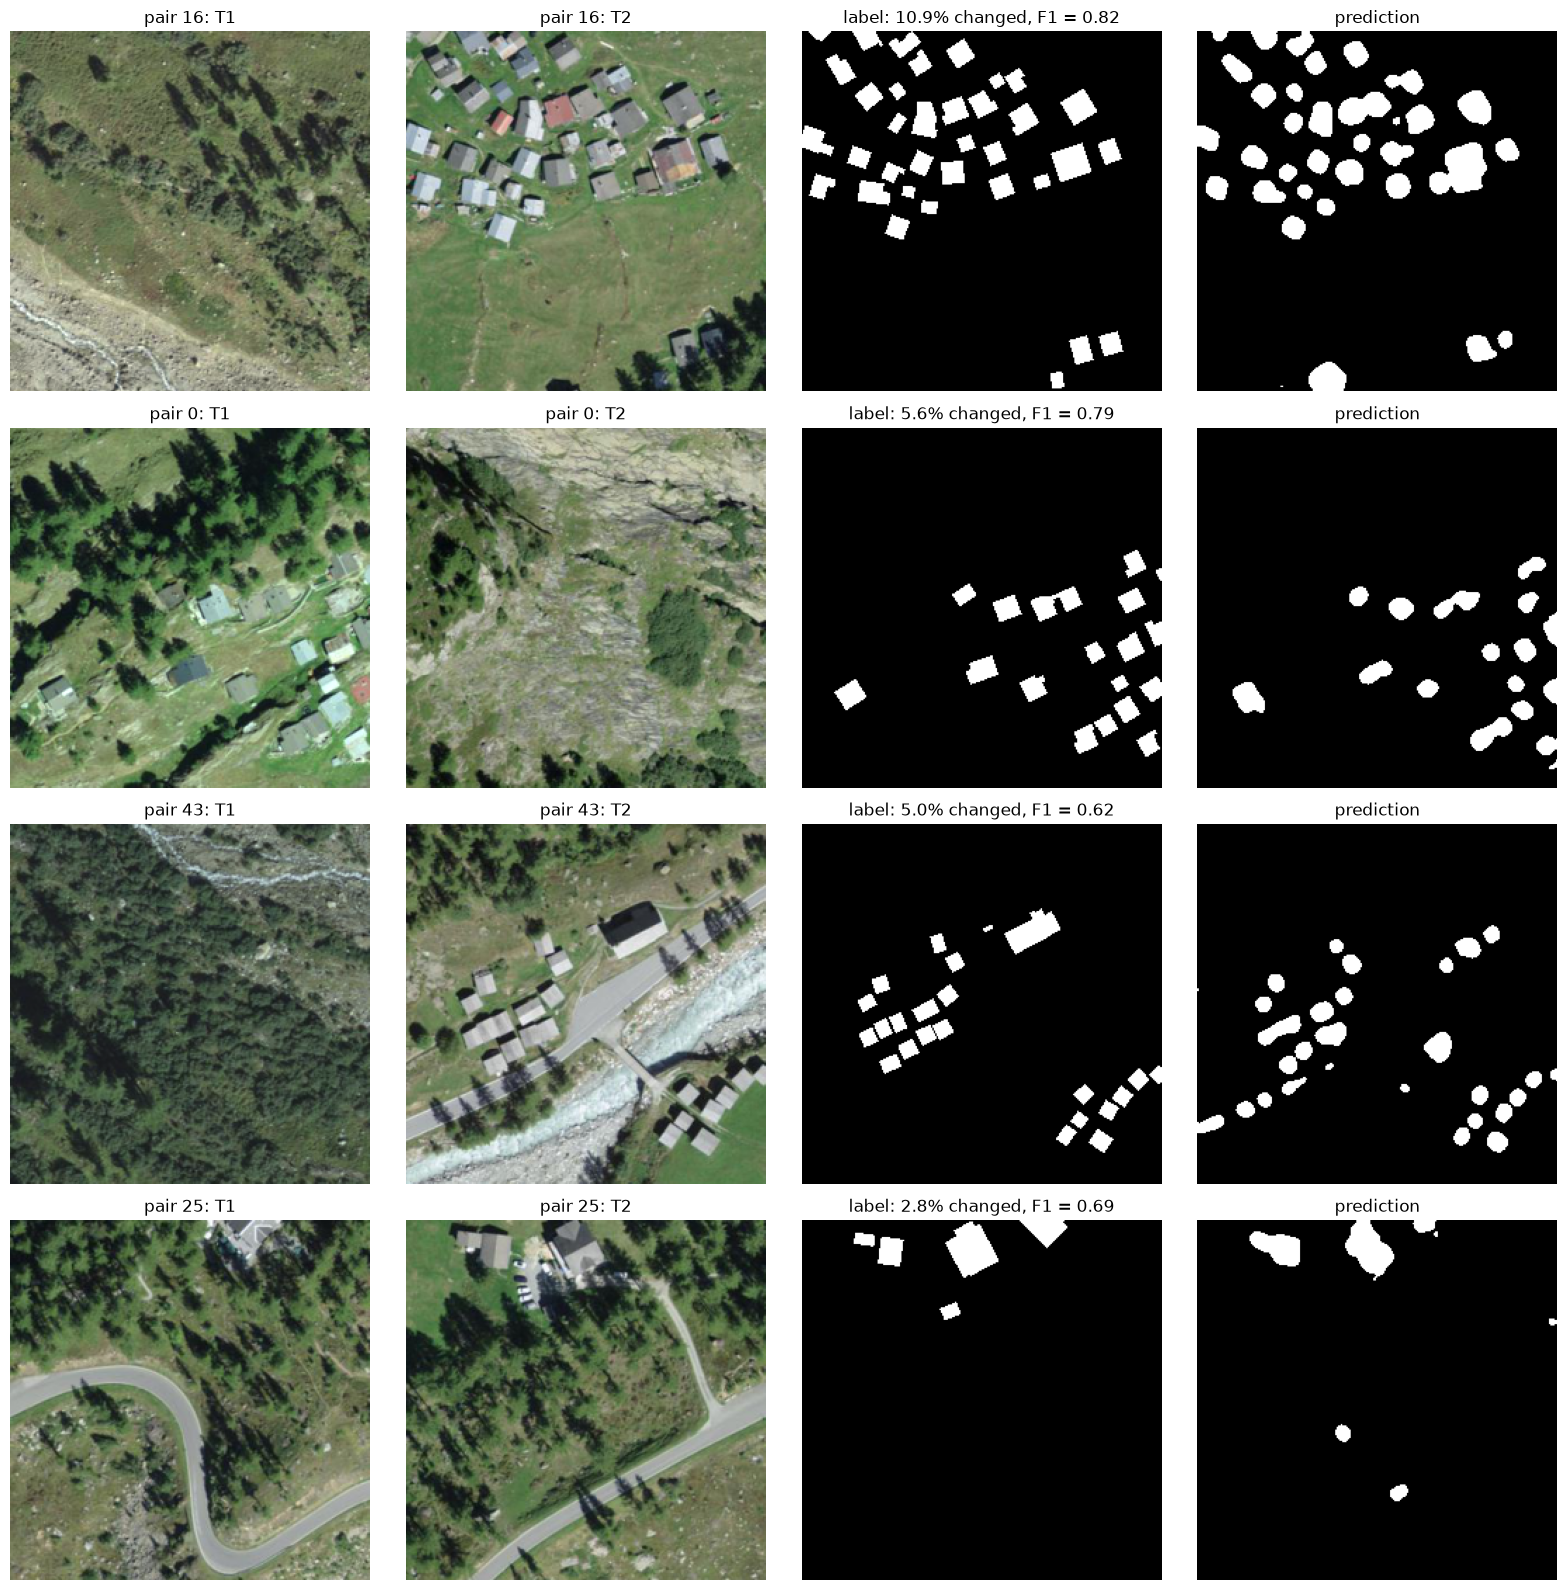

In [12]:
change_fraction = test_mask.float().mean(dim=(1, 2))
order = change_fraction.argsort(descending=True).tolist()
show = order[:4]  # order[-4:] shows pairs with the least change
titles = [f"label: {100 * change_fraction[i]:.1f}% changed, F1 = {scores(test_prob[i], test_mask[i], threshold)['F1-score']:.2f}"
          for i in show]
show_pairs(datamodule.test_dataset, show, predictions=[(test_prob[i] > threshold).float() for i in show], titles=titles)

Same-place pairs (no change at all) are the other half of the story: how many pixels does the model
flag when only light, colour and alignment differ?

In [13]:
same_place = [i for i in range(len(test_mask)) if test_mask[i].sum() == 0]
false_alarm = np.mean([(test_prob[i] > threshold).float().mean().item() for i in same_place])
print(f"Test pairs without any change: {len(same_place)}; flagged pixels on them: {100 * false_alarm:.2f}%")

Test pairs without any change: 33; flagged pixels on them: 0.13%


### J. Compare your experiments and save the model for notebook 3

In [14]:
results_file = OUT_DIR / "results.csv"
final = scores(test_prob, test_mask, threshold)
row = {
    "model": f"{MODEL}-{BACKBONE}",
    "patch": PATCH_SIZE,
    "augment": AUGMENT,
    "same_place": SAME_PLACE_FRACTION,
    "photometric": PHOTOMETRIC,
    "loss": LOSS,
    "frozen": FREEZE_BACKBONE,
    "seed": SEED,
    "epochs": trainer.current_epoch,
    "threshold": threshold,
    "F1@0.5": round(scores(test_prob, test_mask, 0.5)["F1-score"], 3),
    "F1": round(final["F1-score"], 3),
    "IoU": round(final["IoU"], 3),
    "checkpoint": checkpoint_callback.best_model_path,
}
results = pd.DataFrame([row])
if results_file.exists():
    results = pd.concat([pd.read_csv(results_file), results], ignore_index=True)
results.to_csv(results_file, index=False)

# Everything notebook 3 needs to apply this model
selected = {
    "experiment": EXPERIMENT,
    "checkpoint": checkpoint_callback.best_model_path,
    "threshold": float(threshold),
    "mean": MEAN.tolist(),
    "std": STD.tolist(),
}
(OUT_DIR / "selected_model.json").write_text(json.dumps(selected, indent=2))
results.drop(columns="checkpoint").sort_values("F1", ascending=False)

,model,patch,augment,same_place,photometric,loss,frozen,seed,epochs,threshold,F1@0.5,F1,IoU
0,fcsiamdiff-resnet18,256,True,0.3,True,dice,False,0,30,0.05,0.67,0.66,0.492


`runs/selected_model.json` points notebook 3 to this run's checkpoint, threshold and normalization.
If you run several experiments, re-run the one you want to use last (or edit the JSON file), and choose
it by its **validation** score, never by its Blatten result.

## 3. Common pitfalls (from page 8, applied here)

- **Judging the detector by accuracy.** Report F1 and IoU of the change class.
- **Tuning on the test set or on Blatten.** Checkpoint, threshold and settings are chosen on Wiler only.
- **Augmenting the dates differently.** Geometric augmentation must be identical for both dates and the
  mask; only the *radiometry* is changed independently, on purpose.
- **Comparing two single runs.** Repeat promising settings with a few seeds before concluding.
- **Forgetting what the synthetic pairs cannot teach.** No training pair contains debris, mud or water
  where a house used to be. How the model reacts to a *destroyed* house is only tested in notebook 3.